# IDB Projects Dataset — Brazil adaptation extract, 2026-08-25

Source: IDB Open Data, DOI `10.60966/ihisavwe`, English Projects resource filtered to Brazil through the DataStore API. Review: `../../README.md`. Need: `2026-09-br-finance-pathways-review`.
Purpose: reproduce the conservative adaptation screen, validate project-stage and amount semantics, and export one pipeline-ready project table.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import build_brazil_adaptation_release as build

RAW_PATH = build.RAW
PROJECT_PATH = build.PROJECT_OUT
pd.set_option('display.max_colwidth', 100)
print({'raw': RAW_PATH, 'output': PROJECT_PATH, 'resource_id': build.RESOURCE_ID})

{'raw': 'sample/idb_projects_brazil_api.json', 'output': 'data/idb_brazil_adaptation_projects.csv', 'resource_id': '814b7b54-477a-4c25-b3bf-6be05412069d'}


## 1. Load raw — zero transformations

The API response is kept in `sample/`. Every field is loaded as published; the builder verifies the response hash, API success flag, declared total and record count before cleaning.

In [2]:
raw = build.load_source()
print(raw.shape)
raw.head(2)

(1750, 29)


,_id,oper_num,oper_nm,apprvl_dt,sign_dt,cntry_cd,cntry_nm,publc_sts_nm,sector_cd,sector_nm,...,modality_cd,modality_nm,facility_typ_cd,facility_typ_nm,envmntl_clssfctn_cd,envmntl_clssfctn_nm,lending_instrmnt_cd,lending_instrmnt_nm,lending_typ_cd,sts_cd
0,198210,BR-G1001,Taua Solar Photovoltaic Pilot Project,2010-11-15 00:00:00.000000000,2010-11-15 00:00:00.000000000,BR,Brazil,Closed,,,...,,,,,C,Likely to cause minimal or no negative environmental and associated social impacts,IIC,IDB Invest,NSG,EXITED
1,198211,BR-G1003,Recovery and Protection of Climate and Biodiversity Services in Brazil,2014-07-31 00:00:00.000000000,2016-01-28 00:00:00.000000000,BR,Brazil,Closed,PA,ENVIRONMENT AND NATURAL DISASTERS,...,,,,,C,Likely to cause minimal or no negative environmental and associated social impacts,,,SG,EXITED


## 2. Clean — rename, type and screen

The builder renames the 29 short API fields to English snake_case, parses dates and USD amounts, and applies the README's conservative screen. Inclusion requires an official adaptation/disaster subsector, explicit climate adaptation/resilience language, or explicit flood, landslide, drought, warning, drainage, erosion-control or resilient-reconstruction evidence. `BR-G1006` is a named exclusion because adaptation appears only in the title of a general IDB strategy; the intervention is low-carbon mobility.

In [3]:
projects = build.clean_projects(raw)
projects[['project_id', 'project_name', 'public_status', 'adaptation_screen_confidence', 'adaptation_screen_terms']].head(10)

,project_id,project_name,public_status,adaptation_screen_confidence,adaptation_screen_terms
0,BR-J0001,IDB CLIMA - Minas for Results Program: Decarbonization and Climate Resilience Increase of the Mi...,Implementation,high,explicit_climate_adaptation_or_resilience
1,BR-L1005,Igarapes de Manaus Environmental-Social Program,Closed,medium,explicit_hazard_or_risk_reduction
2,BR-L1057,PROCIDADES - Vitória Urban Development and Social Inclusion Program,Closed,medium,explicit_hazard_or_risk_reduction
3,BR-L1058,PROCIDADES - Comprehensive Urban Development Program Município of Nova Iguaçu,Cancelled,medium,explicit_hazard_or_risk_reduction
4,BR-L1335,Environmental Rehabilitation Belo Horizonte - DRENURBS - Suplementar to First Stage,Closed,medium,explicit_hazard_or_risk_reduction
5,BR-L1369,Sanitation for Nova Estrada Watershed - PROMABEN II,Implementation,medium,adaptation_or_disaster_subsector;explicit_hazard_or_risk_reduction
6,BR-L1497,Vitória Urban Improvement and Citizen Security Program (First Stage of the Sustainable Vitória A...,Implementation,high,explicit_climate_adaptation_or_resilience
7,BR-L1508,"Environmental Sanitation, Macrodrainage, and Recovery Project for the Igarapés and the Banks of ...",Implementation,medium,adaptation_or_disaster_subsector;explicit_hazard_or_risk_reduction
8,BR-L1542,"Integrated Project for Water Security, Environmental Sustainability and Socio-productive Develop...",Implementation,high,explicit_climate_adaptation_or_resilience
9,BR-L1608,"Integrated Project for Water Security, Environmental Sustainability and Socio-productive Develop...",Closed,high,explicit_climate_adaptation_or_resilience


## 3. Validate — assertions before export

The validation fixes the release boundary at 1,750 Brazil records and 63 screened candidates, checks project identifiers, stage counts, amount signs, language status and duplicates.

In [4]:
mapping = build.build_mapping(projects)
build.validate(raw, projects, mapping)
print('ALL ASSERTIONS PASSED')

ALL ASSERTIONS PASSED


## 4. Export

The restartable builder writes the project table and the separately governed adaptation crosswalk. The project table contains English source text only; no Portuguese values exist in this resource, so `translation_status` records that no `_pt` pairing is applicable.

In [5]:
build.main()
exported = pd.read_csv(PROJECT_PATH, dtype=str, keep_default_na=False)
assert exported.shape == projects.astype(object).shape
print(exported.shape, PROJECT_PATH)

wrote 63 projects and 78 mapping rows; 36/63 projects mapped to 13 actions
(63, 35) data/idb_brazil_adaptation_projects.csv


## 5. Visualise and test fit

Charts separate lifecycle status and operation type because a preparation-stage operation is not an approved award, and a technical cooperation amount is not comparable to a loan envelope.

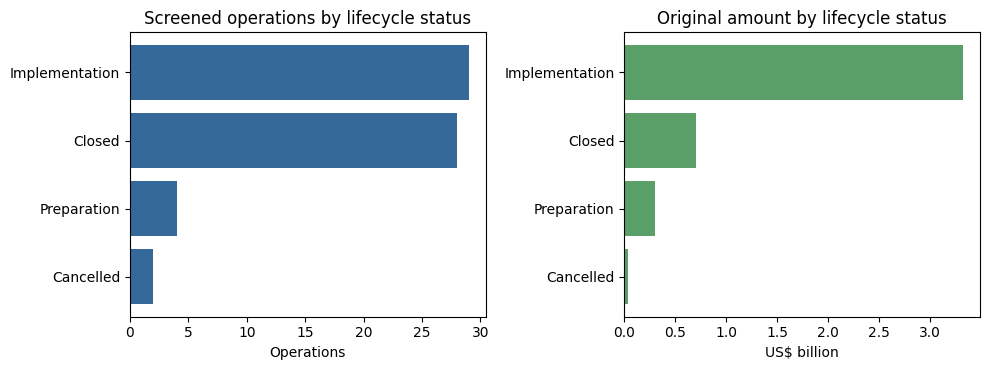

,projects,amount_usd
public_status,,
Cancelled,2,3.525000e+07
Preparation,4,3.038750e+08
Closed,28,6.998729e+08
Implementation,29,3.320783e+09


In [6]:
status = projects.groupby('public_status').agg(projects=('project_id', 'size'), amount_usd=('original_approved_amount_usd', 'sum')).sort_values('amount_usd')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].barh(status.index, status['projects'], color='#34699a')
axes[0].set_title('Screened operations by lifecycle status')
axes[0].set_xlabel('Operations')
axes[1].barh(status.index, status['amount_usd'] / 1e9, color='#5b9f68')
axes[1].set_title('Original amount by lifecycle status')
axes[1].set_xlabel('US$ billion')
fig.tight_layout()
plt.show()
status

In [7]:
fit = pd.DataFrame({
    'check': ['Brazil filter', 'native project id', 'approved-stage separation', 'structured city recipient', 'disbursements', 'official adaptation flag'],
    'result': ['pass', 'pass', 'pass', 'fail', 'fail', 'conditional'],
    'evidence': ['all country_code=BR', '63 unique project_id values', 'status retained; 4 preparation and 2 cancelled', 'no municipality or recipient field', 'original approved amount only', 'subsector for some; reproducible text screen for the rest'],
})
fit

,check,result,evidence
0,Brazil filter,pass,all country_code=BR
1,native project id,pass,63 unique project_id values
2,approved-stage separation,pass,status retained; 4 preparation and 2 cancelled
3,structured city recipient,fail,no municipality or recipient field
4,disbursements,fail,original approved amount only
5,official adaptation flag,conditional,subsector for some; reproducible text screen for the rest


## 6. Findings

The release contains 63 candidate operations: 33 with explicit climate-adaptation/resilience evidence or the dedicated adaptation subsector, and 30 with disaster-risk or hazard evidence. It includes 29 implementation, 28 closed, 4 preparation and 2 cancelled records. The original amount sums to US$4.36 billion across all stages, but this must not be described as adaptation investment because the screen does not allocate each operation's amount to adaptation and preparation/cancelled records are not approved awards.

The source provides no structured city, beneficiary, disbursement, component-cost or official climate-finance share. It supports a searchable portfolio and route precedents, not city-level flows or executed investment.